# Лабораторная работа № 3. Регрессионный анализ
**Вариант 4**

Цель: изучить алгоритмы регрессии на практике, сравнить их качество и интерпретировать результаты.

Части 1–2 используют лист `var4` файла `regression.xlsx`, часть 3 — `salary.csv`.
Ноутбук выполняется сверху вниз. Графики сохраняются в `utility/figures`, таблицы — в
`utility/results`. Для запуска в Colab загрузите оба файла данных рядом с ноутбуком.
При отсутствии библиотек выполните в отдельной ячейке
`%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl`.

Для всех случайных разбиений и алгоритмов с параметром `random_state` принят сид 42.
У `LinearRegression`, `PolynomialFeatures` и `KNeighborsRegressor` этого параметра нет:
они детерминированы при фиксированных данных. Четверть объектов оставляется для тестирования.

In [1]:
# Шаг: 00_подготовка
from pathlib import Path
import json
import sys
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'regression.xlsx').exists() and (p / 'salary.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Положите regression.xlsx и salary.csv рядом с ноутбуком.')
FIG = ROOT / 'utility' / 'figures'
RES = ROOT / 'utility' / 'results'
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
versions = {p: importlib.metadata.version(p) for p in
            ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'openpyxl']}
print('Python:', platform.python_version())
print('Версии библиотек:', versions)

def savefig(name):
    plt.gcf().savefig(FIG / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close('all')

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

def save_table(frame, name):
    frame.to_csv(RES / f'{name}.csv', index=True, encoding='utf-8-sig')

def fact_prediction(ax, actual, predicted, title):
    low = min(np.min(actual), np.min(predicted))
    high = max(np.max(actual), np.max(predicted))
    ax.scatter(actual, predicted, s=20, alpha=.55)
    ax.plot([low, high], [low, high], color='red', label='Идеальный прогноз y = x')
    ax.set(xlabel='Фактическое значение', ylabel='Предсказанное значение', title=title)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect('equal', adjustable='box')
    ax.legend(fontsize=8)

Python: 3.14.7
Версии библиотек: {'numpy': '2.5.1', 'pandas': '3.0.3', 'matplotlib': '3.11.1', 'seaborn': '0.13.2', 'scikit-learn': '1.9.1', 'openpyxl': '3.1.5'}


## 1 Простая линейная регрессия
### 1.1 Данные, описательная статистика и корреляция
Строятся две отдельные модели: `y = a·x1 + b` и `y = a·x2 + b`.
Корреляция Пирсона описывает линейную связь; малое значение не исключает нелинейной связи
и не доказывает отсутствие всех зависимостей.

Размер данных: (1000, 3)


,x1,x2,y
0,0.1876,0.8781,-0.7915
1,0.2071,0.8315,-0.7538
2,0.1574,0.1559,-0.2966
3,-0.1257,0.1183,-0.1204
4,-0.0680,0.8445,-1.2785
5,0.0948,0.3835,-0.1676
6,0.6806,0.3998,0.0600
7,-0.0131,0.5326,-0.3952
8,0.5798,0.6208,-0.9600
9,-0.0734,0.4539,-0.6631


,x1,x2,y
count,"1,000.0000","1,000.0000","1,000.0000"
mean,0.1940,0.6130,-0.5601
std,0.3555,0.3407,0.5537
min,-1.0396,-0.4927,-2.6633
25%,-0.0359,0.3870,-0.9239
50%,0.1960,0.6084,-0.5537
75%,0.4380,0.8461,-0.2094
max,1.3179,1.6819,1.1565


Пропуски: {'x1': 0, 'x2': 0, 'y': 0} Дубликаты: 0


,x1,x2,y
x1,1.0000,-0.0006,-0.0300
x2,-0.0006,1.0000,-0.5131
y,-0.0300,-0.5131,1.0000


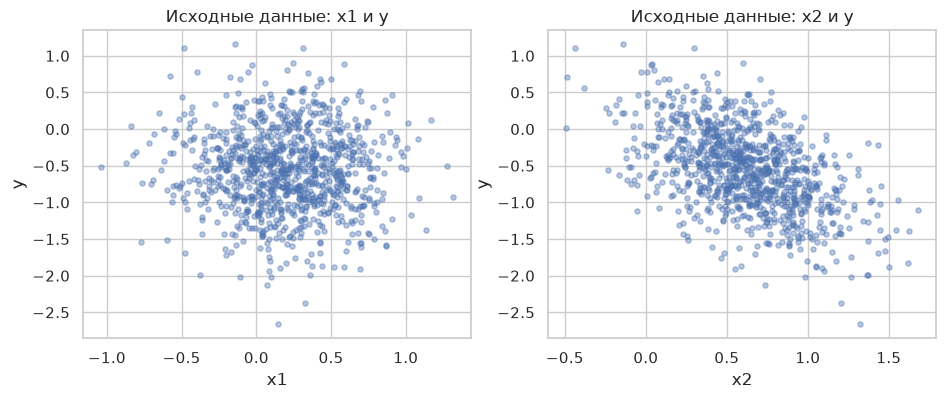

**Предварительный вывод.** r(x1, y) = -0.0300: линейная связь практически отсутствует. r(x2, y) = -0.5131: умеренная отрицательная линейная связь. Причинная связь этим не устанавливается.

In [2]:
# Шаг: 01_данные_статистика_корреляция
df = pd.read_excel(ROOT / 'regression.xlsx', sheet_name='var4')
assert list(df.columns) == ['x1', 'x2', 'y']
print('Размер данных:', df.shape)
display(df.head(10))
display(df.describe())
print('Пропуски:', df.isna().sum().to_dict(), 'Дубликаты:', df.duplicated().sum())
assert df.notna().all().all()
corr = df.corr(method='pearson')
display(corr)
save_table(df.describe(), 'part1_describe')
save_table(corr, 'part1_correlations')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ['x1', 'x2']):
    ax.scatter(df[feature], df.y, alpha=.4, s=14)
    ax.set(xlabel=feature, ylabel='y', title=f'Исходные данные: {feature} и y')
savefig('01_initial_relations')
display(Markdown(f'**Предварительный вывод.** r(x1, y) = {corr.loc["x1", "y"]:.4f}: '
                 f'линейная связь практически отсутствует. r(x2, y) = {corr.loc["x2", "y"]:.4f}: '
                 'умеренная отрицательная линейная связь. Причинная связь этим не устанавливается.'))

### 1.2 Разделение выборки, обучение и предсказания
Один набор индексов используется для всех моделей частей 1–2: так сравнение проводится
на одинаковых объектах. Модели обучаются только на тренировочной части.
Таблицы содержат `факт`, `прогноз` и разность `прогноз − факт`; полные таблицы сохранены в CSV.

In [3]:
# Шаг: 02_линейные_прогнозы_метрики_коэффициенты
train_idx, test_idx = train_test_split(df.index, test_size=.25,
                                     random_state=SEED)
train, test = df.loc[train_idx], df.loc[test_idx]
print('Обучение:', len(train), 'Тест:', len(test))
linear_models, linear_predictions, rows = {}, {}, []
for feature in ['x1', 'x2']:
    model = LinearRegression()  # Детерминированная модель: параметра random_state нет.
    model.fit(train[[feature]], train.y)
    pred = model.predict(test[[feature]])
    linear_models[feature] = model
    result = pd.DataFrame({'факт': test.y, 'прогноз': pred, 'прогноз − факт': pred-test.y})
    linear_predictions[feature] = result
    display(Markdown(f'**Прогноз по {feature}**'))
    display(result)
    save_table(result, f'part1_predictions_{feature}')
    rows.append({'Признак': feature, 'a': model.coef_[0], 'b': model.intercept_,
                 **metrics(test.y, pred), 'R2 train': model.score(train[[feature]], train.y)})
linear_metrics = pd.DataFrame(rows).set_index('Признак')
display(linear_metrics)
save_table(linear_metrics, 'part1_metrics')
for feature, model in linear_models.items():
    print(f'{feature}: y = {model.coef_[0]:.6f} · {feature} {model.intercept_:+.6f}')

Обучение: 750 Тест: 250


**Прогноз по x1**

,факт,прогноз,прогноз − факт
521,0.1144,-0.5468,-0.6612
737,-1.5490,-0.5784,0.9706
740,-0.6544,-0.5405,0.1138
660,-0.6104,-0.5676,0.0429
411,-1.4591,-0.5280,0.9311
...,...,...,...
109,-0.8079,-0.4859,0.3220
430,-0.3583,-0.5257,-0.1675
77,0.0764,-0.5456,-0.6220
84,-1.1953,-0.4975,0.6978


**Прогноз по x2**

,факт,прогноз,прогноз − факт
521,0.1144,-0.3539,-0.4683
737,-1.5490,-0.9605,0.5885
740,-0.6544,-0.4843,0.1700
660,-0.6104,-0.1235,0.4869
411,-1.4591,-1.0206,0.4385
...,...,...,...
109,-0.8079,-0.3508,0.4571
430,-0.3583,-1.0157,-0.6574
77,0.0764,-0.4341,-0.5106
84,-1.1953,-0.5631,0.6322


,a,b,MSE,MAE,RMSE,R2,R2 train
Признак,,,,,,,
x1,-0.0761,-0.5250,0.2982,0.4376,0.5461,-0.0293,0.0024
x2,-0.8549,-0.0226,0.2253,0.3789,0.4747,0.2221,0.2709


x1: y = -0.076077 · x1 -0.525040
x2: y = -0.854928 · x2 -0.022564


### 1.3 Визуализация двух линейных моделей
Показаны исходные наблюдения и обученная прямая, ошибки тестовых прогнозов и диаграмма
«факт — прогноз». На последней одинаковые масштабы осей обеспечивают угол 45° линии `y = x`.
Здесь и далее остатки для графиков определяются как `прогноз − факт`.

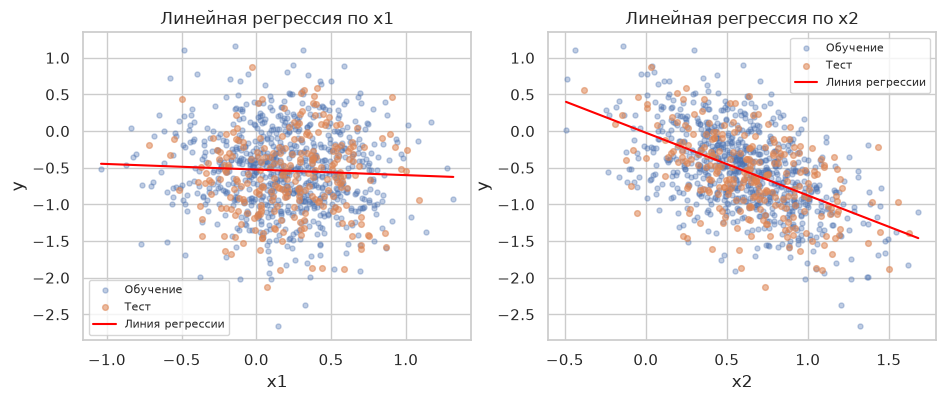

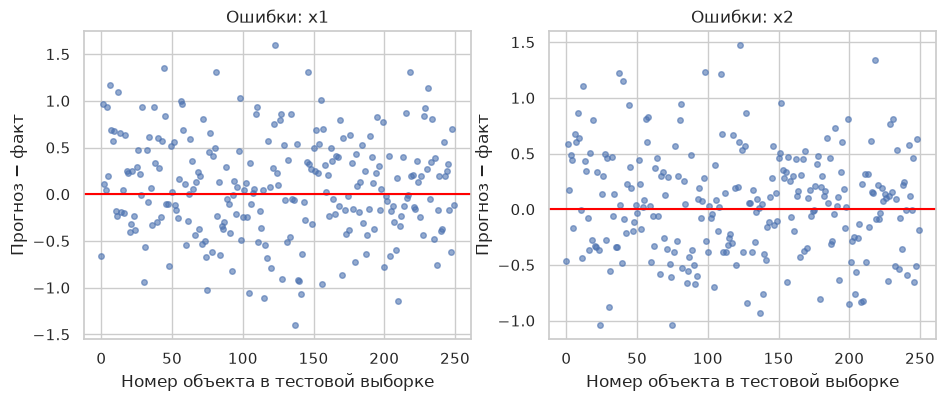

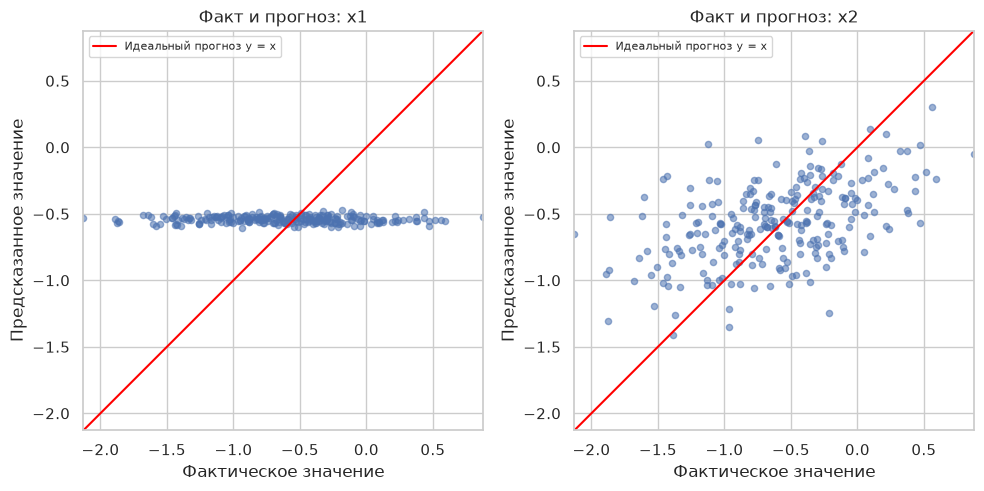

**Вывод по части 1.** Для x1 R² на тесте равен -0.0293, для x2 — 0.2221. Модель по x2 точнее, но существенная часть вариации y остаётся необъяснённой. Отрицательный R² означает результат хуже постоянного прогноза, равного среднему y тестовой выборки. MAE и RMSE измеряются в единицах y, MSE — в квадрате этих единиц; RMSE сильнее реагирует на большие ошибки.

In [4]:
# Шаг: 03_линейные_графики_вывод
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ['x1', 'x2']):
    grid = np.linspace(df[feature].min(), df[feature].max(), 300)
    ax.scatter(train[feature], train.y, s=13, alpha=.35, label='Обучение')
    ax.scatter(test[feature], test.y, s=17, alpha=.55, label='Тест')
    ax.plot(grid, linear_models[feature].predict(pd.DataFrame({feature: grid})),
            color='red', label='Линия регрессии')
    ax.set(xlabel=feature, ylabel='y', title=f'Линейная регрессия по {feature}')
    ax.legend(fontsize=8)
savefig('02_linear_regression')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ['x1', 'x2']):
    ax.scatter(np.arange(len(test)), linear_predictions[feature]['прогноз − факт'], s=16, alpha=.6)
    ax.axhline(0, color='red')
    ax.set(xlabel='Номер объекта в тестовой выборке', ylabel='Прогноз − факт', title=f'Ошибки: {feature}')
savefig('03_linear_errors')
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, feature in zip(axes, ['x1', 'x2']):
    fact_prediction(ax, test.y, linear_predictions[feature]['прогноз'], f'Факт и прогноз: {feature}')
plt.tight_layout()
savefig('04_linear_fact_prediction')
display(Markdown(
    f'**Вывод по части 1.** Для x1 R² на тесте равен {linear_metrics.loc["x1", "R2"]:.4f}, '
    f'для x2 — {linear_metrics.loc["x2", "R2"]:.4f}. '
    'Модель по x2 точнее, но существенная часть вариации y остаётся необъяснённой. '
    'Отрицательный R² означает результат хуже постоянного прогноза, равного среднему y тестовой выборки. '
    'MAE и RMSE измеряются в единицах y, MSE — в квадрате этих единиц; '
    'RMSE сильнее реагирует на большие ошибки.'))

## 2 Полиномиальная регрессия
### 2.1 Выбор признака и степени
Вариант 4 не гарантирует выраженную нелинейность. Проверим, есть ли польза от полинома,
а не будем заранее утверждать её наличие. Кандидаты — оба признака и степени 2, 3, 4, 5.
Выбор осуществляется по среднему R² пятиблочной перекрёстной проверки **только на обучающих данных**.
Тестовая выборка в выборе не участвует. Степень 1 дана как линейный ориентир.

In [5]:
# Шаг: 04_полином_выбор_по_CV
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
selection_rows = []
for feature in ['x1', 'x2']:
    for degree in [1, 2, 3, 4, 5]:
        candidate = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                                  StandardScaler(), LinearRegression())
        scores = cross_val_score(candidate, train[[feature]], train.y, cv=cv, scoring='r2')
        selection_rows.append({'Признак': feature, 'Степень': degree,
                               'R2 CV': scores.mean(), 'SD CV': scores.std()})
selection = pd.DataFrame(selection_rows)
display(selection)
save_table(selection, 'part2_cv_selection')
best = selection.loc[selection['Степень'].ge(2)].sort_values('R2 CV', ascending=False).iloc[0]
poly_feature, best_degree = str(best['Признак']), int(best['Степень'])
print('Признак для полиномиальной регрессии:', poly_feature)
print('Выбранная по CV степень:', best_degree)

,Признак,Степень,R2 CV,SD CV
0,x1,1,-0.0063,0.0080
1,x1,2,-0.0063,0.0076
2,x1,3,-0.0070,0.0083
3,x1,4,-0.0069,0.0098
4,x1,5,-0.0080,0.0108
5,x2,1,0.2619,0.0440
6,x2,2,0.2634,0.0399
7,x2,3,0.2595,0.0419
8,x2,4,0.2628,0.0413
9,x2,5,0.2608,0.0399


Признак для полиномиальной регрессии: x2
Выбранная по CV степень: 2


### 2.2 Обучение, сравнение степеней и графики
Для выбранного признака строим модели степеней 1–5. Для каждой выводим R² и MAE
на обучении и тесте. Параметр `include_bias=False` исключает дублирование свободного члена.
Масштабирование полиномиальных признаков обучается внутри конвейера.

,R2 train,R2 test,MAE train,MAE test,R2 CV
Степень,,,,,
1,0.2709,0.2221,0.3796,0.3789,0.2619
2,0.2745,0.2128,0.3785,0.3818,0.2634
3,0.2745,0.2125,0.3785,0.3818,0.2595
4,0.2791,0.2088,0.3767,0.3828,0.2628
5,0.2791,0.2088,0.3766,0.3828,0.2608


,факт,прогноз,прогноз − факт
521,0.1144,-0.3409,-0.4553
737,-1.5490,-0.9848,0.5642
740,-0.6544,-0.4627,0.1917
660,-0.6104,-0.1482,0.4622
411,-1.4591,-1.0594,0.3997
...,...,...,...
109,-0.8079,-0.3381,0.4698
430,-0.3583,-1.0532,-0.6949
77,0.0764,-0.4147,-0.4912
84,-1.1953,-0.5406,0.6547


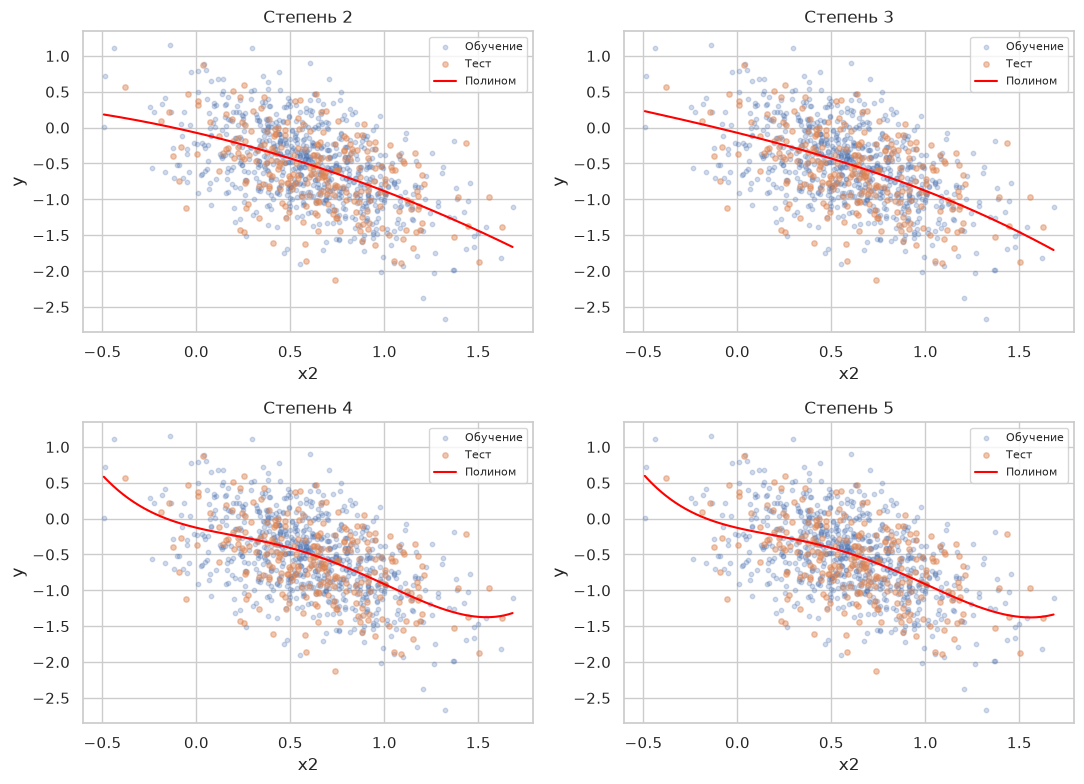

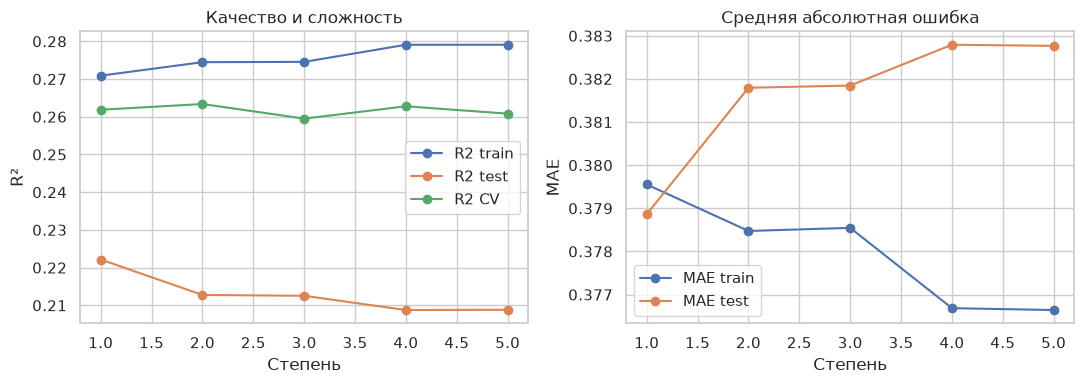

**Вывод по части 2.** По перекрёстной проверке выбраны x2 и степень 2. Для этой модели R² test = 0.2128, MAE test = 0.3818. Повышение степени не гарантирует улучшения на новых данных. Слишком низкая степень может приводить к недообучению, слишком высокая — к переобучению и неустойчивому поведению на краях диапазона. Оптимальную степень выбирают по валидации; при близком качестве предпочтительнее более простая модель. Небольшие различия CV на одном разбиении сами по себе не доказывают превосходства.

Квадратичная модель по x2 имеет немного больший средний R² CV, чем линейная, но на отложенном тесте её R² ниже, а MAE выше. Степень 2 выбрана по CV; небольшое преимущество CV не подтверждает устойчивого практического улучшения на новых данных.

In [6]:
# Шаг: 05_полином_метрики_графики_вывод
poly_models, poly_rows = {}, []
for degree in [1, 2, 3, 4, 5]:
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                          StandardScaler(), LinearRegression())
    model.fit(train[[poly_feature]], train.y)
    pred_train = model.predict(train[[poly_feature]])
    pred_test = model.predict(test[[poly_feature]])
    poly_models[degree] = model
    cv_value = selection.query('Признак == @poly_feature and Степень == @degree')['R2 CV'].iloc[0]
    poly_rows.append({'Степень': degree, 'R2 train': r2_score(train.y, pred_train),
                     'R2 test': r2_score(test.y, pred_test),
                     'MAE train': mean_absolute_error(train.y, pred_train),
                     'MAE test': mean_absolute_error(test.y, pred_test), 'R2 CV': cv_value})
poly_metrics = pd.DataFrame(poly_rows).set_index('Степень')
display(poly_metrics)
save_table(poly_metrics, 'part2_metrics')
poly_pred = poly_models[best_degree].predict(test[[poly_feature]])
poly_predictions = pd.DataFrame({'факт': test.y, 'прогноз': poly_pred, 'прогноз − факт': poly_pred-test.y})
display(poly_predictions)
save_table(poly_predictions, 'part2_predictions')
grid = np.linspace(df[poly_feature].min(), df[poly_feature].max(), 400)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, degree in zip(axes.flat, [2, 3, 4, 5]):
    ax.scatter(train[poly_feature], train.y, s=10, alpha=.25, label='Обучение')
    ax.scatter(test[poly_feature], test.y, s=15, alpha=.45, label='Тест')
    ax.plot(grid, poly_models[degree].predict(pd.DataFrame({poly_feature: grid})),
            color='red', label='Полином')
    ax.set(xlabel=poly_feature, ylabel='y', title=f'Степень {degree}')
    ax.legend(fontsize=8)
plt.tight_layout()
savefig('05_polynomial_degrees')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
poly_metrics[['R2 train', 'R2 test', 'R2 CV']].plot(ax=axes[0], marker='o')
poly_metrics[['MAE train', 'MAE test']].plot(ax=axes[1], marker='o')
axes[0].set(ylabel='R²', title='Качество и сложность')
axes[1].set(ylabel='MAE', title='Средняя абсолютная ошибка')
plt.tight_layout()
savefig('06_polynomial_metrics')
display(Markdown(
    f'**Вывод по части 2.** По перекрёстной проверке выбраны {poly_feature} и степень {best_degree}. '
    f'Для этой модели R² test = {poly_metrics.loc[best_degree, "R2 test"]:.4f}, '
    f'MAE test = {poly_metrics.loc[best_degree, "MAE test"]:.4f}. '
    'Повышение степени не гарантирует улучшения на новых данных. '
    'Слишком низкая степень может приводить к недообучению, слишком высокая — к переобучению '
    'и неустойчивому поведению на краях диапазона. Оптимальную степень выбирают по валидации; '
    'при близком качестве предпочтительнее более простая модель. '
    'Небольшие различия CV на одном разбиении сами по себе не доказывают превосходства.'))
display(Markdown(
    'Квадратичная модель по x2 имеет немного больший средний R² CV, чем линейная, но на отложенном тесте её R² ниже, а MAE выше. Степень 2 выбрана по CV; небольшое преимущество CV не подтверждает устойчивого практического улучшения на новых данных.'))

## 3 Прогнозирование годовой зарплаты
### 3.1 Понимание данных и целевая переменная
Целевая переменная — `salary` (годовая зарплата), а `income` — прежний годовой доход,
который является входным признаком. Числовые признаки: возраст, прежний доход, опыт,
результат теста, рабочие часы, расстояние до работы, сбережения и долги.
Категориальные признаки: образование, город, сфера работы, семейное положение,
наличие автомобиля и удалённая работа.

Размер набора: (1500, 15)


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,"70,201.1897",25,87.5597,62,3.7087,"25,987.3340","2,556.8216",PhD,Chicago,Finance,Single,Yes,Yes,"106,233.8335"
1,69,"51,901.8974",39,70.8084,36,7.0828,"22,134.8990",725.1805,High School,Houston,Retail,Single,No,Yes,"87,205.2910"
2,46,"38,605.4093",4,63.3250,77,5.1292,"47,106.0684","12,659.3596",PhD,Los Angeles,Finance,Married,Yes,No,"69,369.2835"
3,32,"49,949.7370",20,78.2155,33,19.3156,"15,868.3288","12,369.7760",Bachelor,Los Angeles,IT,Married,Yes,No,"76,587.1170"
4,60,"48,965.2901",13,74.4291,48,5.6549,"15,734.6333","4,792.0952",Bachelor,Phoenix,IT,Married,No,No,"71,023.1488"
5,25,"11,326.7686",3,73.0228,39,4.8792,"11,916.7440","6,431.8359",Bachelor,Los Angeles,IT,Single,No,Yes,"49,665.6096"
6,38,"41,579.4971",22,87.1631,49,11.7061,"33,558.5890","12,271.3305",PhD,Chicago,Retail,Single,No,Yes,"92,451.8668"
7,56,"54,713.0560",19,76.6714,38,9.2241,"32,785.0437","4,876.9065",Bachelor,New York,Retail,Single,Yes,Yes,"77,558.7556"
8,36,"43,636.7665",14,77.6357,72,1.1345,"40,287.7956","5,796.9293",Master,Phoenix,Healthcare,Married,Yes,No,"70,917.6491"
9,40,"40,306.8596",28,71.7295,58,7.0962,"9,083.2125","12,941.3844",Master,New York,IT,Married,No,No,"83,196.2152"


<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1500 non-null   int64  
 1   income            1500 non-null   float64
 2   experience        1500 non-null   int64  
 3   score_test        1500 non-null   float64
 4   hours_worked      1500 non-null   int64  
 5   distance_to_work  1500 non-null   float64
 6   savings           1500 non-null   float64
 7   debt              1500 non-null   float64
 8   education         1500 non-null   str    
 9   city              1500 non-null   str    
 10  job_type          1500 non-null   str    
 11  marital_status    1500 non-null   str    
 12  car               1500 non-null   str    
 13  remote_work       1500 non-null   str    
 14  salary            1500 non-null   float64
dtypes: float64(6), int64(3), str(6)
memory usage: 175.9 KB


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
count,"1,500.0000","1,500.0000","1,500.0000","1,500.0000","1,500.0000","1,500.0000","1,500.0000","1,500.0000",1500,1500,1500,1500,1500,1500,"1,500.0000"
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,5,5,3,2,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Bachelor,New York,Retail,Married,Yes,Yes,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,900,600,500,717,1050,883,NaN
mean,43.7320,"50,493.5622",19.4793,74.6499,49.0460,10.1692,"19,920.7230","7,656.7493",NaN,NaN,NaN,NaN,NaN,NaN,"98,573.0935"
std,15.0718,"15,354.4957",11.4715,9.9044,17.0537,10.0031,"13,635.5301","5,481.3904",NaN,NaN,NaN,NaN,NaN,NaN,"111,786.7560"
min,18.0000,-826.4212,0.0000,41.6050,20.0000,0.0181,408.4820,4.3671,NaN,NaN,NaN,NaN,NaN,NaN,"28,588.9843"
25%,31.0000,"40,525.9897",10.0000,67.7761,34.0000,3.0222,"9,418.7079","3,138.4842",NaN,NaN,NaN,NaN,NaN,NaN,"69,582.6549"
50%,44.0000,"50,784.6906",19.0000,74.7016,49.0000,7.1052,"17,114.5125","6,786.7038",NaN,NaN,NaN,NaN,NaN,NaN,"80,310.4128"
75%,56.0000,"61,104.9980",29.0000,81.6356,63.0000,14.3921,"27,766.2140","11,008.3096",NaN,NaN,NaN,NaN,NaN,NaN,"91,637.0526"


,Тип,Пропуски,Уникальных
age,int64,0,52
income,float64,0,1500
experience,int64,0,40
score_test,float64,0,1500
hours_worked,int64,0,60
distance_to_work,float64,0,1500
savings,float64,0,1500
debt,float64,0,1500
education,str,0,4
city,str,0,5


Полных дубликатов: 0


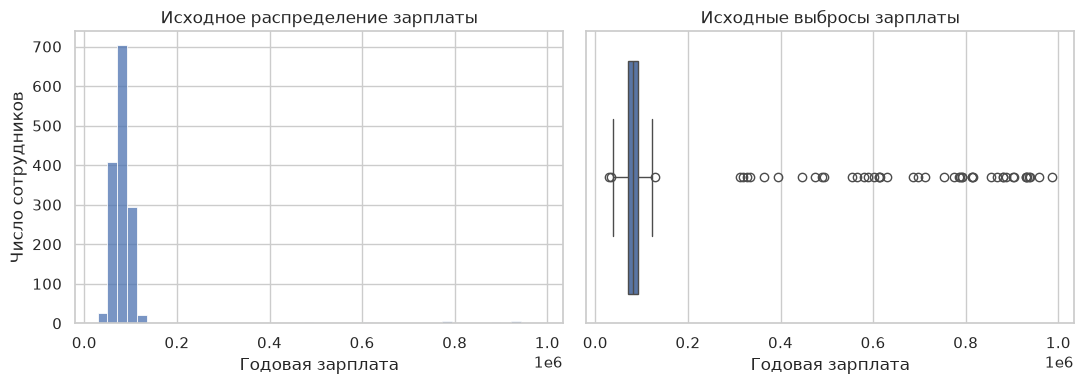

In [7]:
# Шаг: 06_зарплата_загрузка_аудит_гистограмма
salary = pd.read_csv(ROOT / 'salary.csv')
print('Размер набора:', salary.shape)
display(salary.head(10))
salary.info()
display(salary.describe(include='all'))
audit = pd.DataFrame({'Тип': salary.dtypes.astype(str), 'Пропуски': salary.isna().sum(),
                      'Уникальных': salary.nunique()})
display(audit)
print('Полных дубликатов:', salary.duplicated().sum())
save_table(audit, 'part3_audit')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(salary.salary, bins=45, ax=axes[0])
axes[0].set(xlabel='Годовая зарплата', ylabel='Число сотрудников', title='Исходное распределение зарплаты')
sns.boxplot(x=salary.salary, ax=axes[1])
axes[1].set(xlabel='Годовая зарплата', title='Исходные выбросы зарплаты')
plt.tight_layout()
savefig('07_salary_initial')

### 3.2 Разбиение и обработка качества данных
Сначала выделяем тестовые объекты. Отрицательный прежний доход считаем некорректным и
заменяем на пропуск по предметному правилу, не используя целевую переменную.
Пропуски затем заполняются медианами, рассчитанными на обучении.

Для числовых входных признаков применяем ограничение по границам Тьюки
`Q1 − 1.5·IQR`, `Q3 + 1.5·IQR`. Квартили оцениваются только на обучении;
эти же границы используются для теста и внутри каждого блока CV.
Для естественно неотрицательных признаков нижняя граница не меньше нуля.
Это ограничивает влияние крайних входных значений и сохраняет все строки.

Крупные значения `salary` автоматически не удаляем и не заменяем: высокие зарплаты
возможны, а без внешнего подтверждения нельзя объявить их ошибками.
Удаление тестовых объектов по зарплате изменило бы оцениваемую задачу.
Далее отдельно покажем качество для обычного диапазона зарплат как дополнительную диагностику.

In [8]:
# Шаг: 07_разбиение_обработка_выбросов
X = salary.drop(columns='salary').copy()
y = salary['salary'].copy()
negative_income_count = int(X.income.lt(0).sum())
X.loc[X.income.lt(0), 'income'] = np.nan
numeric = X.select_dtypes(include='number').columns.tolist()
categorical = [c for c in X if c not in numeric]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.25, random_state=SEED)
print('Числовые признаки:', numeric)
print('Категориальные признаки:', categorical)
print('Отрицательных income заменено на пропуск:', negative_income_count)
print('Обучение:', X_train.shape, 'Тест:', X_test.shape)

class IQRClipper(TransformerMixin, BaseEstimator):
    """Границы ограничений оцениваются при fit только на обучающих объектах."""
    def fit(self, X, y=None):
        arr = np.asarray(X, dtype=float)
        q1, q3 = np.nanquantile(arr, [.25, .75], axis=0)
        self.lower_ = np.maximum(0, q1 - 1.5 * (q3-q1))
        self.upper_ = q3 + 1.5 * (q3-q1)
        self.n_features_in_ = arr.shape[1]
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('clip', IQRClipper()),
    ('scale', StandardScaler())])
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))])
preprocessor = ColumnTransformer([
    ('число', numeric_pipeline, numeric),
    ('категория', categorical_pipeline, categorical)], verbose_feature_names_out=False)
diagnostic_prep = clone(preprocessor).fit(X_train)
num_pipe = diagnostic_prep.named_transformers_['число']
imputed_train = num_pipe.named_steps['impute'].transform(X_train[numeric])
clipper = num_pipe.named_steps['clip']
clipped_train = clipper.transform(imputed_train)
outlier_table = pd.DataFrame({
    'Нижняя граница': clipper.lower_, 'Верхняя граница': clipper.upper_,
    'Изменено train': np.sum(imputed_train != clipped_train, axis=0)}, index=numeric)
display(outlier_table)
save_table(outlier_table, 'part3_outlier_bounds')
train_q1, train_q3 = y_train.quantile([.25, .75])
target_low = train_q1 - 1.5*(train_q3-train_q1)
target_high = train_q3 + 1.5*(train_q3-train_q1)
print(f'Границы salary по обучению: [{target_low:.2f}; {target_high:.2f}]')
print('Точек salary вне границ в обучении:', int((~y_train.between(target_low, target_high)).sum()))
print('Все значения целевой переменной сохранены.')

Числовые признаки: ['age', 'income', 'experience', 'score_test', 'hours_worked', 'distance_to_work', 'savings', 'debt']
Категориальные признаки: ['education', 'city', 'job_type', 'marital_status', 'car', 'remote_work']
Отрицательных income заменено на пропуск: 1
Обучение: (1125, 14) Тест: (375, 14)


,Нижняя граница,Верхняя граница,Изменено train
age,0.0000,93.5000,0
income,"10,935.8853","90,921.7467",7
experience,0.0000,59.0000,0
score_test,47.2052,102.0354,8
hours_worked,0.0000,105.0000,0
distance_to_work,0.0000,31.3535,54
savings,0.0000,"54,292.4965",28
debt,0.0000,"22,696.8355",10


Границы salary по обучению: [36490.42; 123826.29]
Точек salary вне границ в обучении: 38
Все значения целевой переменной сохранены.


### 3.3 Визуализация после обработки и матрица рассеяния
Сравниваем распределения числовых признаков на обучении до и после ограничения.
Зарплата сохраняется, поэтому её распределение после обработки совпадает с исходным.
Матрица рассеяния содержит все 9 количественных переменных; категории кодируются
для моделей, но не подменяются непрерывными числами в этой матрице.

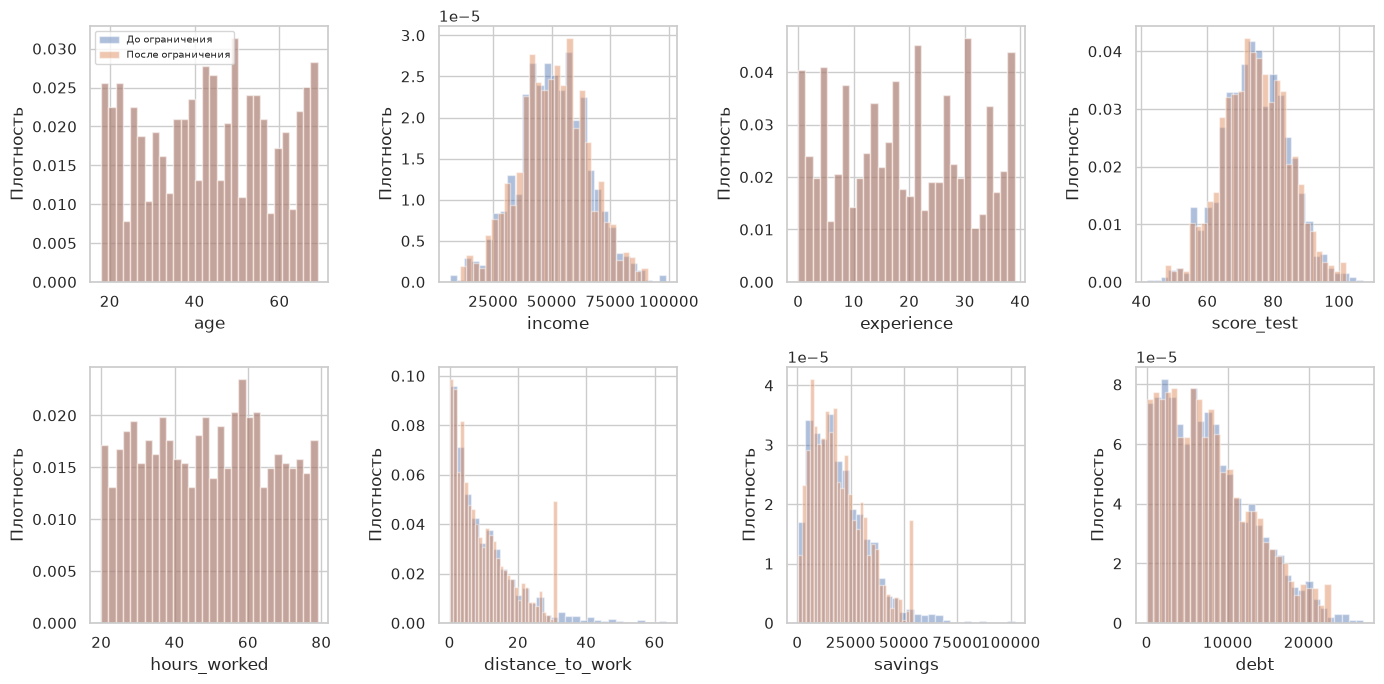

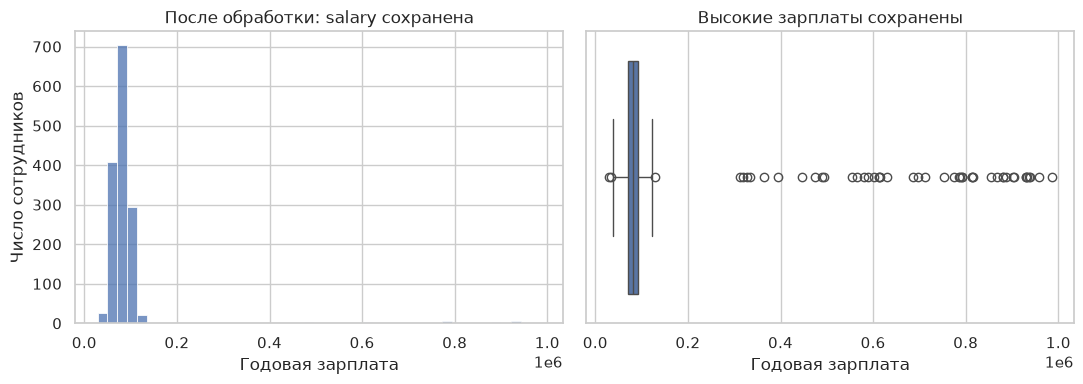

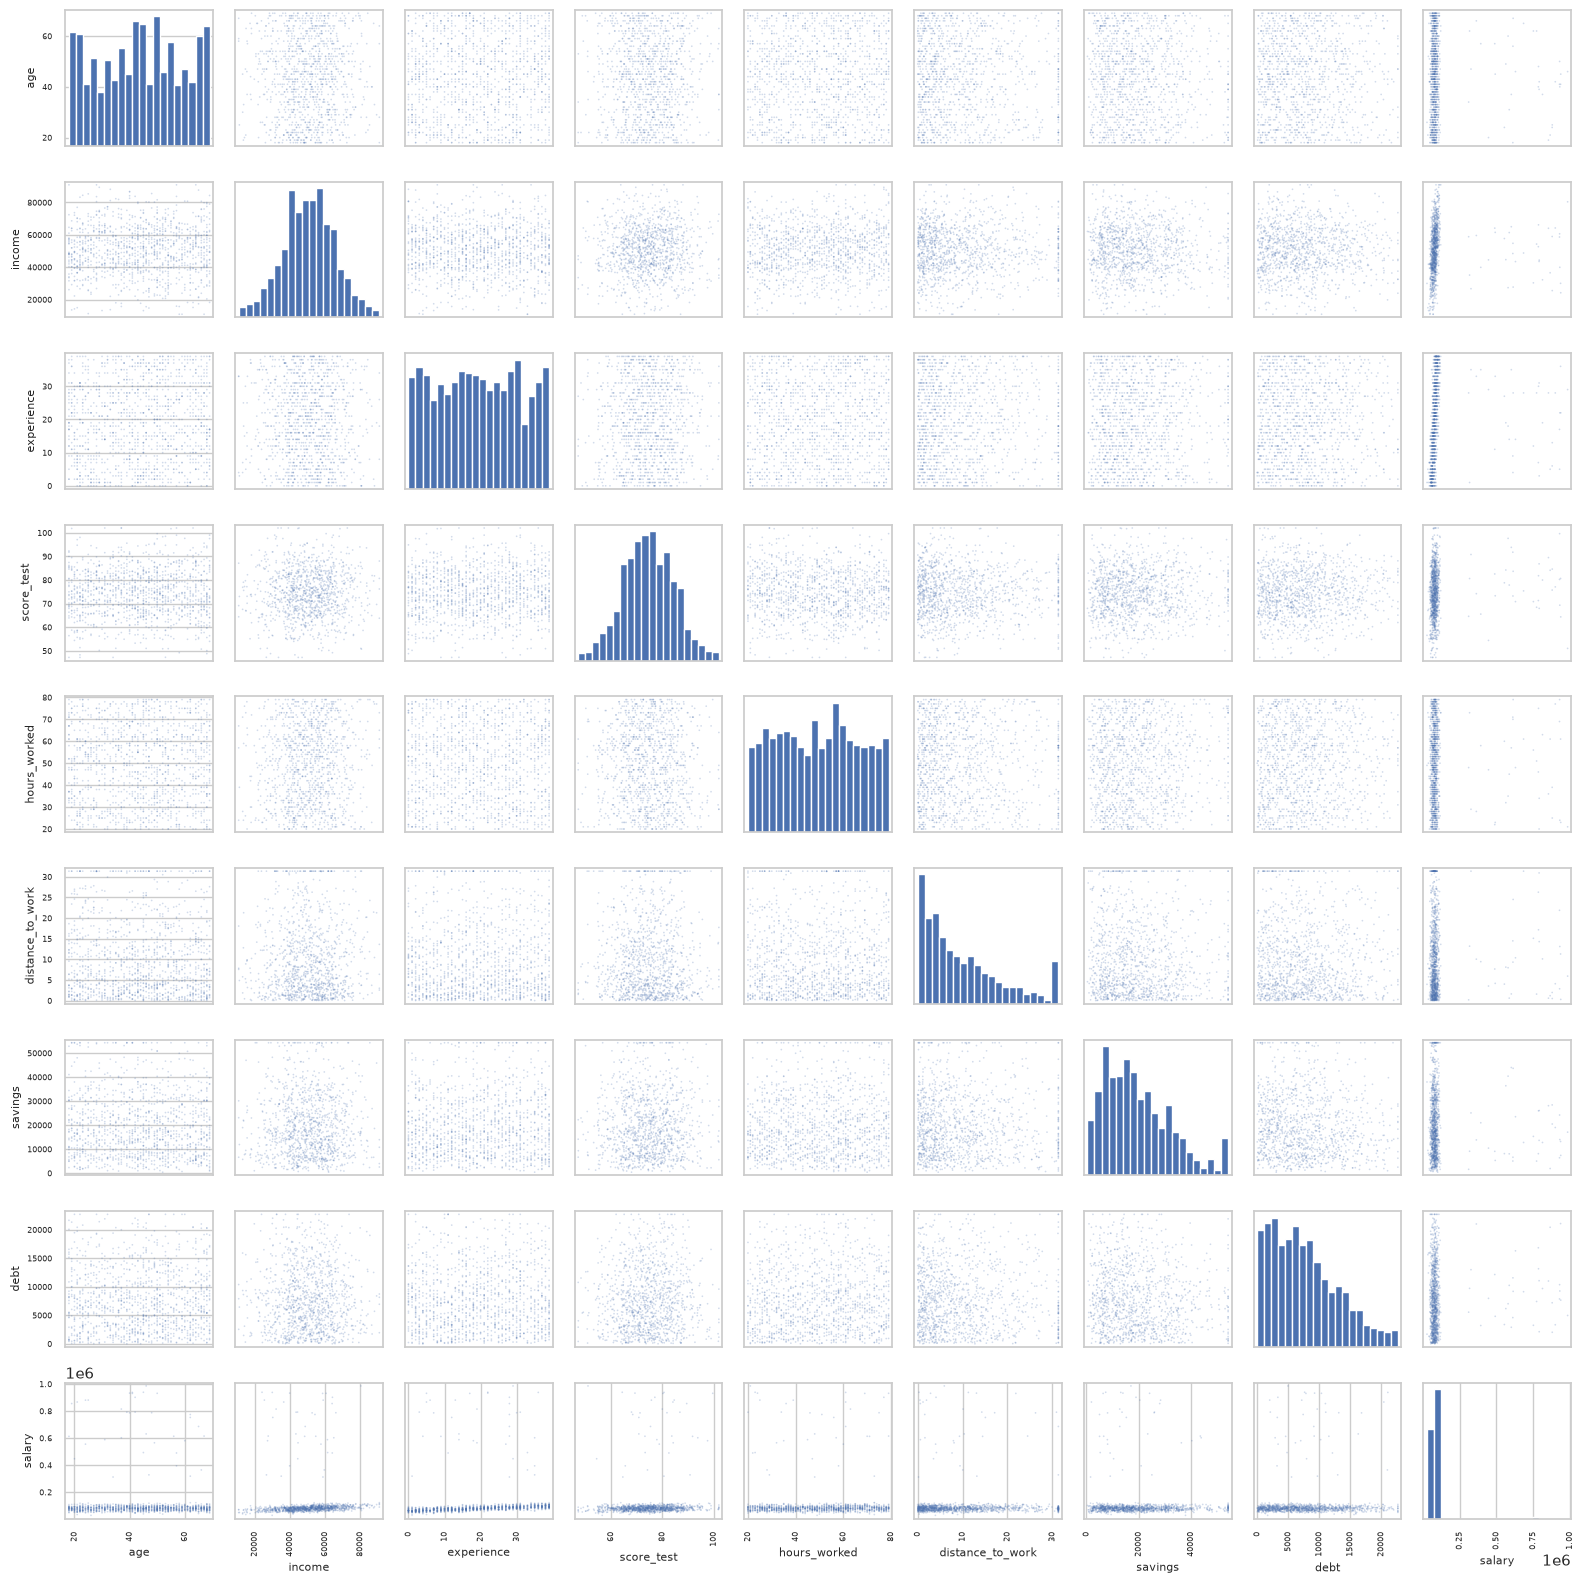

In [9]:
# Шаг: 08_после_обработки_матрица_рассеяния
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for j, (ax, feature) in enumerate(zip(axes.flat, numeric)):
    ax.hist(imputed_train[:, j], bins=30, alpha=.45, density=True, label='До ограничения')
    ax.hist(clipped_train[:, j], bins=30, alpha=.45, density=True, label='После ограничения')
    ax.set(xlabel=feature, ylabel='Плотность')
    if j == 0: ax.legend(fontsize=7)
plt.tight_layout()
savefig('08_features_before_after')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(salary.salary, bins=45, ax=axes[0])
axes[0].set(xlabel='Годовая зарплата', ylabel='Число сотрудников', title='После обработки: salary сохранена')
sns.boxplot(x=salary.salary, ax=axes[1])
axes[1].set(xlabel='Годовая зарплата', title='Высокие зарплаты сохранены')
plt.tight_layout()
savefig('09_salary_after')
scatter_data = pd.DataFrame(clipped_train, columns=numeric, index=X_train.index)
scatter_data['salary'] = y_train
axes = pd.plotting.scatter_matrix(scatter_data, figsize=(16, 16), diagonal='hist',
                                  alpha=.25, s=6, hist_kwds={'bins': 20})
for ax in axes.flat:
    ax.xaxis.label.set_size(8)
    ax.yaxis.label.set_size(8)
    ax.tick_params(labelsize=6)
plt.tight_layout()
savefig('10_salary_scatter_matrix')

### 3.4 Кодирование, масштабирование и линейная модель
Категории кодируются One-Hot с удалением базовой категории (`drop='first'`).
Числовые признаки стандартизуются после заполнения и ограничения выбросов.
Все преобразования входят в `Pipeline`: при проверке по блокам они обучаются заново
только на тренировочных объектах соответствующего блока.

,факт,прогноз,прогноз − факт
1116,"51,903.8583","74,260.6280","22,356.7698"
1368,"95,326.9094","107,215.0836","11,888.1742"
422,"90,717.6153","108,159.5313","17,441.9161"
413,"84,107.8471","76,964.1427","-7,143.7044"
451,"62,854.2208","81,663.1938","18,808.9730"
...,...,...,...
155,"64,178.5397","91,737.3338","27,558.7941"
1151,"95,939.0850","110,116.7334","14,177.6483"
1141,"84,172.2914","128,191.3387","44,019.0474"
974,"89,227.8423","93,202.7623","3,974.9201"


,MSE,MAE,RMSE,R2
Линейная регрессия,"11,257,018,176.0274","34,974.9239","106,099.0960",-0.0119


Размер после кодирования: (1125, 23)


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education_High School,education_Master,education_PhD,city_Houston,city_Los Angeles,city_New York,city_Phoenix,job_type_Finance,job_type_Healthcare,job_type_IT,job_type_Retail,marital_status_Married,marital_status_Single,car_Yes,remote_work_Yes
807,-0.5840,-0.5928,0.4902,0.1490,1.3854,0.8087,2.7346,-0.5529,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000
1229,-1.2504,-0.4064,1.2664,0.8964,-1.3694,-0.1917,-1.1187,-1.4096,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000,1.0000
1480,-1.1838,-1.7761,-1.5799,-0.8922,0.4476,0.2828,0.4908,-1.3887,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000
1436,0.4158,-0.0741,0.9214,0.2852,-1.6625,0.3586,-0.3011,0.0536,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000
179,1.0156,-0.6486,-1.3212,0.0106,-0.9591,-1.0408,-0.4148,-1.0569,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000
1355,-0.9172,-0.6039,-0.4586,0.1867,-0.1385,1.9724,-1.3687,1.5072,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000
1246,-1.4504,-0.5252,1.0077,-2.6504,-1.5452,-0.1763,0.2640,0.7090,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1040,-0.0508,-0.6778,0.9214,0.8520,-0.6074,-0.5704,0.3227,-0.7394,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000
949,-1.4504,-0.6202,-0.6311,-0.1387,0.6234,-0.9484,0.1115,-0.1579,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000
816,0.0159,1.6623,-1.5799,0.6639,-0.6660,-0.7202,-0.9921,1.4407,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000


,Признак,Коэффициент,Модуль коэффициента
0,education_PhD,"17,588.4542","17,588.4542"
1,education_Master,"15,951.0713","15,951.0713"
2,job_type_Healthcare,"10,886.2921","10,886.2921"
3,experience,"10,646.1707","10,646.1707"
4,car_Yes,"-9,226.3108","9,226.3108"
5,job_type_Retail,"8,727.5755","8,727.5755"
6,marital_status_Single,"-8,114.3506","8,114.3506"
7,remote_work_Yes,"8,017.3066","8,017.3066"
8,score_test,"7,661.9150","7,661.9150"
9,marital_status_Married,"-7,356.0950","7,356.0950"


Свободный член: 97794.29292258018
Базовые категории: {'education': 'Bachelor', 'city': 'Chicago', 'job_type': 'Education', 'marital_status': 'Divorced', 'car': 'No', 'remote_work': 'No'}


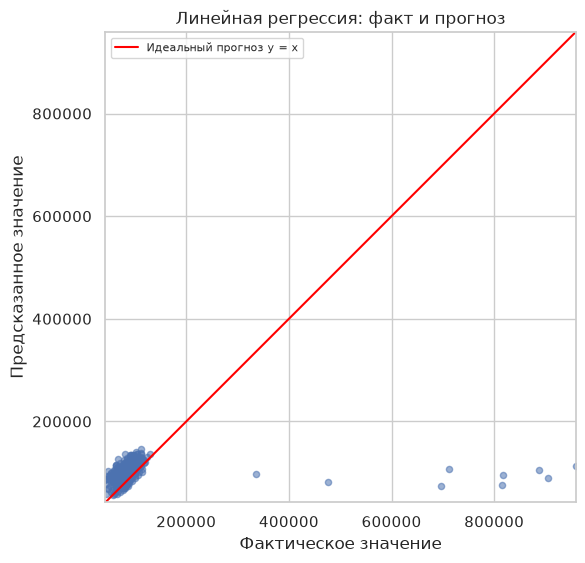

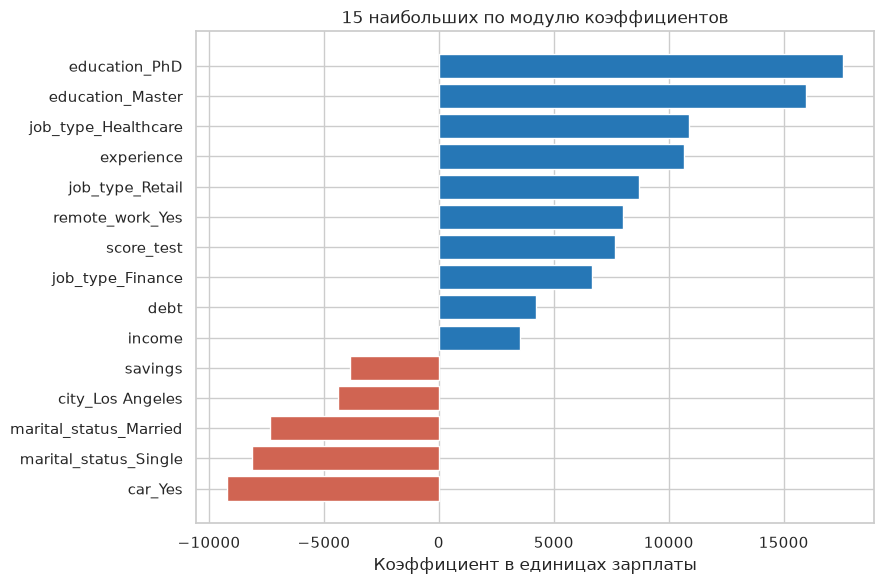

Коэффициент числового признака описывает изменение прогноза при увеличении обработанного признака на одно стандартное отклонение, при прочих равных. Коэффициент категории — разность с базовой категорией. Прямое сравнение величин числовых и категориальных коэффициентов условно: их масштабы различны. Большой модуль коэффициента не доказывает причинность или устойчивую важность; на оценки влияют корреляции и крупные значения целевой переменной.

In [10]:
# Шаг: 09_зарплата_линейная_коэффициенты
linear_salary = Pipeline([('prep', clone(preprocessor)), ('model', LinearRegression())])
linear_salary.fit(X_train, y_train)
salary_linear_pred = linear_salary.predict(X_test)
salary_linear_predictions = pd.DataFrame({'факт': y_test, 'прогноз': salary_linear_pred,
                                         'прогноз − факт': salary_linear_pred-y_test})
display(salary_linear_predictions)
save_table(salary_linear_predictions, 'part3_linear_predictions')
display(pd.DataFrame([metrics(y_test, salary_linear_pred)], index=['Линейная регрессия']))
transformed = linear_salary.named_steps['prep'].transform(X_train)
feature_names = linear_salary.named_steps['prep'].get_feature_names_out()
print('Размер после кодирования:', transformed.shape)
display(pd.DataFrame(transformed, columns=feature_names, index=X_train.index).head(10))
coef = pd.DataFrame({'Признак': feature_names, 'Коэффициент': linear_salary.named_steps['model'].coef_})
coef['Модуль коэффициента'] = coef['Коэффициент'].abs()
coef = coef.sort_values('Модуль коэффициента', ascending=False).reset_index(drop=True)
display(coef)
print('Свободный член:', linear_salary.named_steps['model'].intercept_)
encoder = linear_salary.named_steps['prep'].named_transformers_['категория'].named_steps['encode']
reference_categories = {c: str(values[0]) for c, values in zip(categorical, encoder.categories_)}
print('Базовые категории:', reference_categories)
save_table(coef, 'part3_linear_coefficients')
fig, ax = plt.subplots(figsize=(6, 6))
fact_prediction(ax, y_test, salary_linear_pred, 'Линейная регрессия: факт и прогноз')
plt.tight_layout()
savefig('11_salary_linear_fact_prediction')
fig, ax = plt.subplots(figsize=(9, 6))
top_coef = coef.head(15).sort_values('Коэффициент')
ax.barh(top_coef['Признак'], top_coef['Коэффициент'],
        color=np.where(top_coef['Коэффициент'] >= 0, '#2677b6', '#d06452'))
ax.set(xlabel='Коэффициент в единицах зарплаты', title='15 наибольших по модулю коэффициентов')
plt.tight_layout()
savefig('12_salary_coefficients')
display(Markdown(
    'Коэффициент числового признака описывает изменение прогноза при увеличении '
    'обработанного признака на одно стандартное отклонение, при прочих равных. '
    'Коэффициент категории — разность с базовой категорией. '
    'Прямое сравнение величин числовых и категориальных коэффициентов условно: их масштабы различны. '
    'Большой модуль коэффициента не доказывает причинность или устойчивую важность; '
    'на оценки влияют корреляции и крупные значения целевой переменной.'))

### 3.5 k ближайших соседей и дерево решений
Параметры подбираются только на обучении по пятиблочной CV с минимизацией MAE.
Для kNN перебираем число соседей и способ взвешивания, для дерева — глубину и минимальное
число объектов в листе. Тест не участвует в подборе.
Постоянный прогноз по медиане обучения используется как дополнительная базовая модель.

In [11]:
# Шаг: 10_knn_дерево_сравнение
searches = {}
specifications = {
    'kNN': (KNeighborsRegressor(),
            {'model__n_neighbors': [5, 15, 35, 75], 'model__weights': ['uniform', 'distance']}),
    'Дерево решений': (
        DecisionTreeRegressor(random_state=SEED),
        {'model__max_depth': [2, 4, 6, None], 'model__min_samples_leaf': [5, 20, 50]})}
for name, (estimator, parameters) in specifications.items():
    pipe = Pipeline([('prep', clone(preprocessor)), ('model', estimator)])
    search = GridSearchCV(pipe, parameters, scoring='neg_mean_absolute_error', cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(name, 'лучшие параметры:', search.best_params_, 'MAE CV:', -search.best_score_)
    cv_table = pd.DataFrame(search.cv_results_)
    save_table(cv_table[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']],
               'part3_cv_knn' if name == 'kNN' else 'part3_cv_tree')
salary_models = {'Линейная регрессия': linear_salary,
                 **{name: search.best_estimator_ for name, search in searches.items()}}
baseline = DummyRegressor(strategy='median').fit(X_train, y_train)
salary_predictions = pd.DataFrame({'факт': y_test})
comparison_rows = []
cv_mae = {'Линейная регрессия': -cross_val_score(
    clone(linear_salary), X_train, y_train, cv=cv, scoring='neg_mean_absolute_error').mean(),
    **{name: -search.best_score_ for name, search in searches.items()}}
recommended = min(cv_mae, key=cv_mae.get)
for name, model in salary_models.items():
    pred = model.predict(X_test)
    salary_predictions[name] = pred
    comparison_rows.append({'Модель': name, **metrics(y_test, pred),
                            'R2 train': model.score(X_train, y_train), 'MAE CV': cv_mae[name]})
base_pred = baseline.predict(X_test)
salary_predictions['Медиана обучения'] = base_pred
comparison_rows.append({'Модель': 'Медиана обучения', **metrics(y_test, base_pred),
                        'R2 train': baseline.score(X_train, y_train),
                        'MAE CV': -cross_val_score(DummyRegressor(strategy='median'), X_train, y_train,
                                                    cv=cv, scoring='neg_mean_absolute_error').mean()})
salary_metrics = pd.DataFrame(comparison_rows).set_index('Модель')
display(salary_metrics)
display(salary_predictions)
save_table(salary_metrics, 'part3_model_comparison')
save_table(salary_predictions, 'part3_all_predictions')
print('Метод, выбранный по MAE CV среди трёх регрессоров:', recommended)

kNN лучшие параметры: {'model__n_neighbors': 75, 'model__weights': 'distance'} MAE CV: 37568.43976823204


Дерево решений лучшие параметры: {'model__max_depth': 2, 'model__min_samples_leaf': 5} MAE CV: 38969.54280920973


,MSE,MAE,RMSE,R2,R2 train,MAE CV
Модель,,,,,,
Линейная регрессия,"11,257,018,176.0274","34,974.9239","106,099.0960",-0.0119,0.0269,"39,499.9080"
kNN,"11,284,591,574.7173","33,153.1660","106,228.9583",-0.0143,1.0000,"37,568.4398"
Дерево решений,"11,246,021,737.7375","33,129.3765","106,047.2618",-0.0109,0.0390,"38,969.5428"
Медиана обучения,"11,395,742,659.3966","28,119.2154","106,750.8438",-0.0243,-0.0276,"31,122.0989"


,факт,Линейная регрессия,kNN,Дерево решений,Медиана обучения
1116,"51,903.8583","74,260.6280","89,177.7400","88,956.3353","80,284.4151"
1368,"95,326.9094","107,215.0836","96,637.6295","88,956.3353","80,284.4151"
422,"90,717.6153","108,159.5313","97,195.7887","88,956.3353","80,284.4151"
413,"84,107.8471","76,964.1427","82,931.2434","88,956.3353","80,284.4151"
451,"62,854.2208","81,663.1938","76,873.8991","88,956.3353","80,284.4151"
...,...,...,...,...,...
155,"64,178.5397","91,737.3338","91,019.8755","88,956.3353","80,284.4151"
1151,"95,939.0850","110,116.7334","86,909.2482","88,956.3353","80,284.4151"
1141,"84,172.2914","128,191.3387","94,938.6712","88,956.3353","80,284.4151"
974,"89,227.8423","93,202.7623","112,483.3329","88,956.3353","80,284.4151"


Метод, выбранный по MAE CV среди трёх регрессоров: kNN


### 3.6 Сравнительные графики и анализ ошибок
Графики всех методов построены по одним и тем же тестовым объектам и в одинаковых
масштабах. График по объектам отсортирован по фактической зарплате для удобства чтения.
Дополнительные метрики на обычном диапазоне используют границы зарплаты, рассчитанные
на обучении, и не заменяют оценку на полной тестовой выборке.

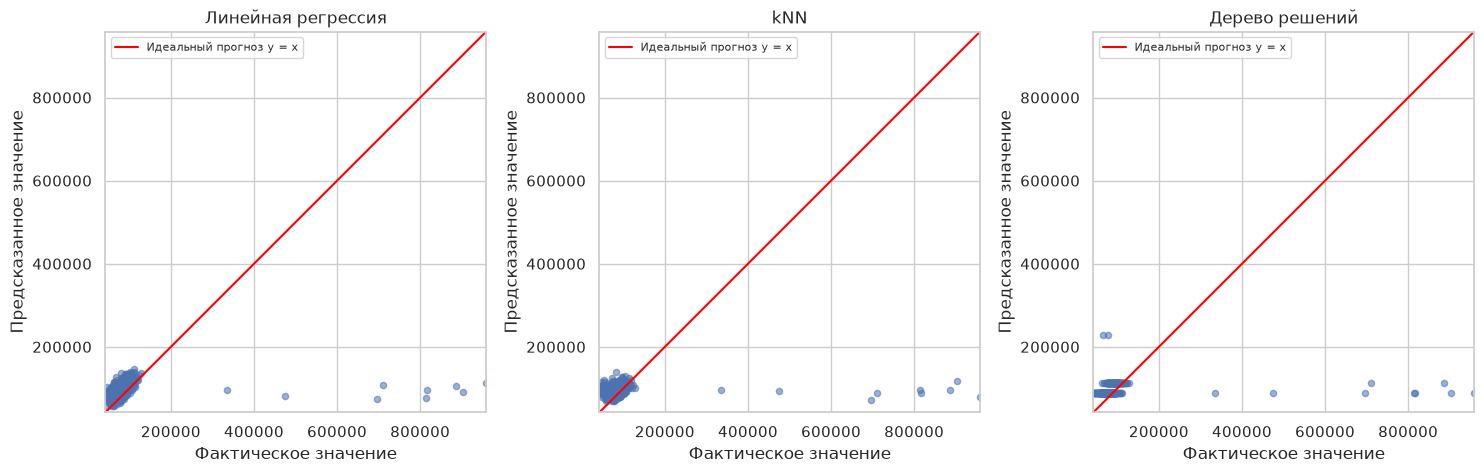

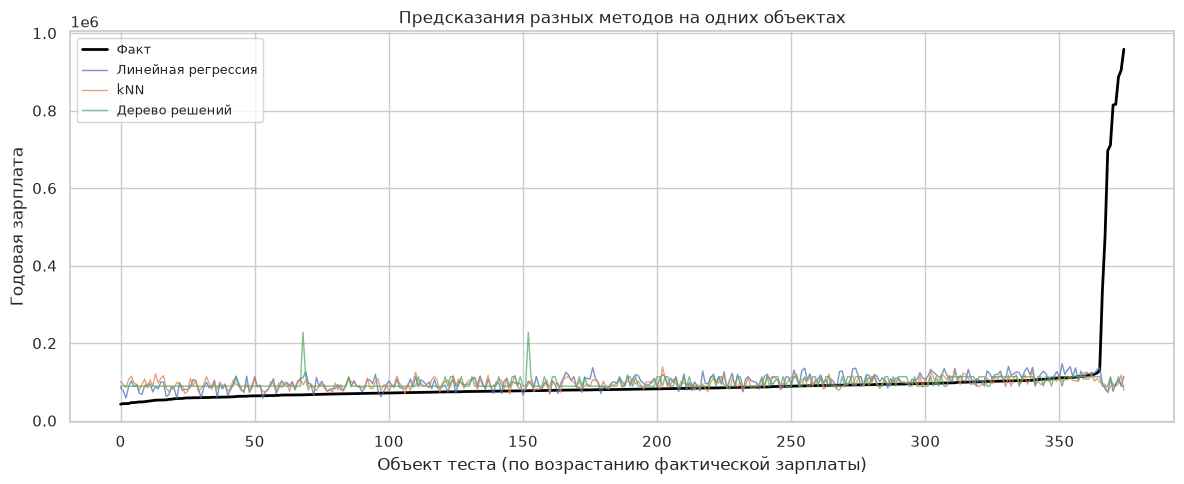

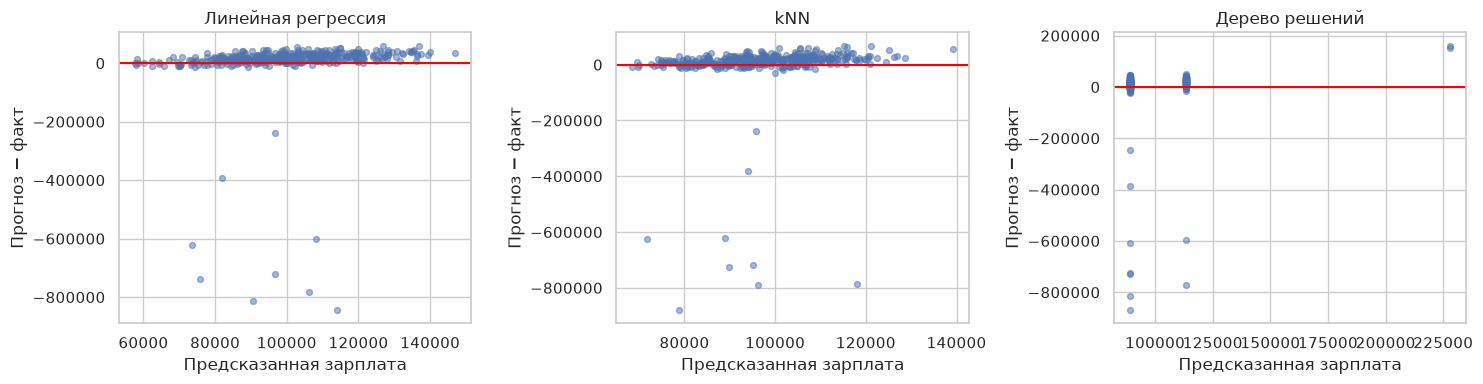

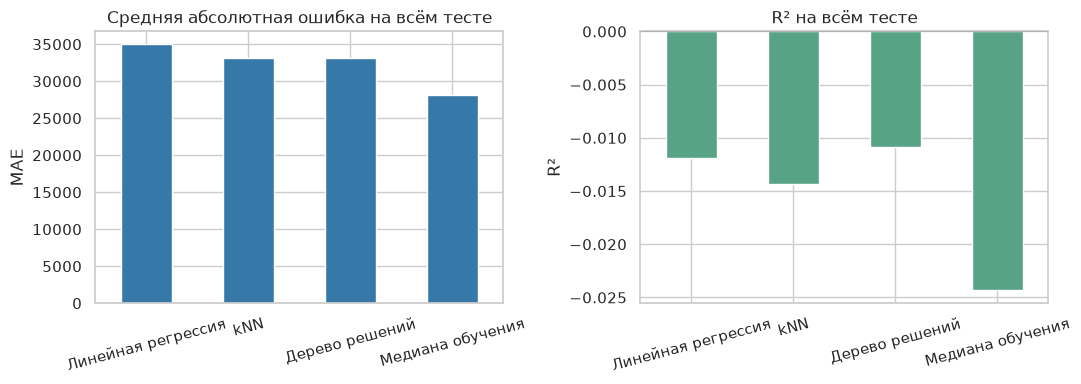

,Модель,Группа,n,MSE,MAE,RMSE,R2
0,Линейная регрессия,Обычный диапазон,365,"574,516,300.5198","20,146.7743","23,969.0697",-1.3133
1,Линейная регрессия,За границами IQR,10,"401,168,336,632.0538","576,202.3836","633,378.5098",-4.9648
2,kNN,Обычный диапазон,365,"515,441,048.9611","18,173.7404","22,703.3268",-1.0754
3,kNN,За границами IQR,10,"404,358,585,764.8191","579,902.2007","635,891.9608",-5.0122
4,Дерево решений,Обычный диапазон,365,"565,274,649.3421","18,244.0712","23,775.5052",-1.2760
5,Дерево решений,За границами IQR,10,"401,093,290,464.1698","576,443.0169","633,319.2642",-4.9637
6,Медиана обучения,Обычный диапазон,365,"248,807,228.2943","12,657.9595","15,773.6245",-0.0018
7,Медиана обучения,За границами IQR,10,"418,258,885,894.6314","592,455.0547","646,729.3761",-5.2189


**Вывод по части 3.** По MAE CV среди обязательных методов выбран «kNN». На всём тесте минимальный MAE среди них у «Дерево решений» (33,129.38), максимальный R² у «Дерево решений» (-0.0109). Из 375 тестовых объектов 10 находятся за границами IQR salary. Редкие большие зарплаты создают значительные ошибки и особенно сильно влияют на MSE и RMSE. Усреднённая метрика не гарантирует точность для таких сотрудников. Преимущество над базовым прогнозом следует проверять по выбранной метрике; ни один метод нельзя рекомендовать к применению без оценки ошибок в разных группах.

**Сравнение с базовым методом.** Медиана обучения имеет меньший MAE на CV и на тесте, чем все три регрессора. Выбор kNN относится только к сравнению обязательных методов; на данном наборе по MAE они не оправдывают замену постоянного медианного прогноза. R² обучения kNN с весами distance близок к 1, поскольку обучающий объект является своим ближайшим соседом. Это не показатель точности на новых объектах.

In [12]:
# Шаг: 11_сравнительные_графики_диагностика
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, salary_models):
    fact_prediction(ax, y_test, salary_predictions[name], name)
plt.tight_layout()
savefig('13_salary_all_fact_prediction')
ordered = salary_predictions.sort_values('факт').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ordered.index, ordered['факт'], color='black', lw=2, label='Факт')
for name in salary_models:
    ax.plot(ordered.index, ordered[name], alpha=.75, lw=1, label=name)
ax.set(xlabel='Объект теста (по возрастанию фактической зарплаты)', ylabel='Годовая зарплата',
       title='Предсказания разных методов на одних объектах')
ax.legend(fontsize=9)
plt.tight_layout()
savefig('14_salary_sorted_predictions')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, salary_models):
    ax.scatter(salary_predictions[name], salary_predictions[name]-y_test, s=18, alpha=.5)
    ax.axhline(0, color='red')
    ax.set(xlabel='Предсказанная зарплата', ylabel='Прогноз − факт', title=name)
plt.tight_layout()
savefig('15_salary_residuals')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
salary_metrics['MAE'].plot.bar(ax=axes[0], rot=15, color='#3678a8')
salary_metrics['R2'].plot.bar(ax=axes[1], rot=15, color='#58a386')
axes[0].set(ylabel='MAE', xlabel='', title='Средняя абсолютная ошибка на всём тесте')
axes[1].set(ylabel='R²', xlabel='', title='R² на всём тесте')
axes[1].axhline(0, color='black', lw=.7)
plt.tight_layout()
savefig('16_salary_comparison_metrics')
typical = y_test.between(target_low, target_high)
diagnostic_rows = []
for name in salary_predictions.columns.drop('факт'):
    diagnostic_rows.append({'Модель': name, 'Группа': 'Обычный диапазон', 'n': int(typical.sum()),
                            **metrics(y_test[typical], salary_predictions.loc[typical, name])})
    if (~typical).sum() > 1:
        diagnostic_rows.append({'Модель': name, 'Группа': 'За границами IQR', 'n': int((~typical).sum()),
                                **metrics(y_test[~typical], salary_predictions.loc[~typical, name])})
diagnostic_metrics = pd.DataFrame(diagnostic_rows)
display(diagnostic_metrics)
save_table(diagnostic_metrics, 'part3_diagnostic_groups')
best_test_mae = salary_metrics.loc[list(salary_models), 'MAE'].idxmin()
best_test_r2 = salary_metrics.loc[list(salary_models), 'R2'].idxmax()
display(Markdown(
    f'**Вывод по части 3.** По MAE CV среди обязательных методов выбран «{recommended}». '
    f'На всём тесте минимальный MAE среди них у «{best_test_mae}» '
    f'({salary_metrics.loc[best_test_mae, "MAE"]:,.2f}), максимальный R² у «{best_test_r2}» '
    f'({salary_metrics.loc[best_test_r2, "R2"]:.4f}). '
    f'Из {len(y_test)} тестовых объектов {int((~typical).sum())} находятся за границами IQR salary. '
    'Редкие большие зарплаты создают значительные ошибки и особенно сильно влияют на MSE и RMSE. '
    'Усреднённая метрика не гарантирует точность для таких сотрудников. '
    'Преимущество над базовым прогнозом следует проверять по выбранной метрике; '
    'ни один метод нельзя рекомендовать к применению без оценки ошибок в разных группах.'))
display(Markdown(
    '**Сравнение с базовым методом.** Медиана обучения имеет меньший MAE на CV и на тесте, '
    'чем все три регрессора. Выбор kNN относится только к сравнению обязательных методов; '
    'на данном наборе по MAE они не оправдывают замену постоянного медианного прогноза. '
    'R² обучения kNN с весами distance близок к 1, поскольку обучающий объект является своим '
    'ближайшим соседом. Это не показатель точности на новых объектах.'))

## 4 Заключение
Численные результаты ниже формируются автоматически из обученных моделей.

In [13]:
# Шаг: 12_заключение_экспорт
conclusion = [
    f'Исследованы 1000 наблюдений варианта 4 и 1500 записей о сотрудниках. '
    f'В первой части сравнивались две парные линейные регрессии: '
    f'для x2 R² test = {linear_metrics.loc["x2", "R2"]:.4f}, '
    f'для x1 R² test = {linear_metrics.loc["x1", "R2"]:.4f}. '
    f'Для полиномиальной модели по CV выбраны признак {poly_feature} и степень {best_degree}; '
    f'её R² test = {poly_metrics.loc[best_degree, "R2 test"]:.4f}.',
    f'Для прогноза salary применены проверка качества, замена отрицательного income на пропуск, '
    f'заполнение медианой, ограничение крайних входных значений по IQR, '
    f'One-Hot-кодирование и стандартизация. Сравнены линейная регрессия, kNN и дерево решений. '
    f'По MAE CV среди этих методов выбран «{recommended}»: '
    f'MAE test = {salary_metrics.loc[recommended, "MAE"]:,.2f}, '
    f'R² test = {salary_metrics.loc[recommended, "R2"]:.4f}. '
    f'Однако медианный базовый прогноз точнее по MAE всех трёх регрессоров.',
    f'Основная трудность — редкие высокие зарплаты и ограниченная предсказательная сила признаков. '
    f'Все целевые значения и {len(y_test)} тестовых объектов сохранены, '
    f'что позволяет видеть ошибки на полном диапазоне. '
    f'Подбор параметров и преобразования выполнены только по обучающей выборке; '
    f'это предотвращает утечку тестовых данных. Для практического применения требуется '
    f'проверка происхождения экстремальных зарплат и сбор дополнительных факторов оплаты труда.'
]
for paragraph in conclusion:
    display(Markdown(paragraph))
summary = {
    'variant': 4, 'seed': SEED, 'versions': versions,
    'linear_metrics': linear_metrics.reset_index().to_dict(orient='records'),
    'poly_feature': poly_feature, 'poly_degree': best_degree,
    'poly_metrics': poly_metrics.reset_index().to_dict(orient='records'),
    'salary_metrics': salary_metrics.reset_index().to_dict(orient='records'),
    'recommended': recommended, 'best_test_mae': best_test_mae, 'best_test_r2': best_test_r2,
    'salary_train_n': len(y_train), 'salary_test_n': len(y_test),
    'atypical_test_n': int((~typical).sum()), 'negative_income_n': negative_income_count,
    'target_bounds': [float(target_low), float(target_high)],
    'reference_categories': reference_categories,
    'conclusion': conclusion,
    'best_parameters': {name: search.best_params_ for name, search in searches.items()}}
(RES / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Графики:', FIG)
print('Таблицы:', RES)

Исследованы 1000 наблюдений варианта 4 и 1500 записей о сотрудниках. В первой части сравнивались две парные линейные регрессии: для x2 R² test = 0.2221, для x1 R² test = -0.0293. Для полиномиальной модели по CV выбраны признак x2 и степень 2; её R² test = 0.2128.

Для прогноза salary применены проверка качества, замена отрицательного income на пропуск, заполнение медианой, ограничение крайних входных значений по IQR, One-Hot-кодирование и стандартизация. Сравнены линейная регрессия, kNN и дерево решений. По MAE CV среди этих методов выбран «kNN»: MAE test = 33,153.17, R² test = -0.0143. Однако медианный базовый прогноз точнее по MAE всех трёх регрессоров.

Основная трудность — редкие высокие зарплаты и ограниченная предсказательная сила признаков. Все целевые значения и 375 тестовых объектов сохранены, что позволяет видеть ошибки на полном диапазоне. Подбор параметров и преобразования выполнены только по обучающей выборке; это предотвращает утечку тестовых данных. Для практического применения требуется проверка происхождения экстремальных зарплат и сбор дополнительных факторов оплаты труда.

Графики: /home/tom1k/Документы/edu/5sem/ida/3/utility/figures
Таблицы: /home/tom1k/Документы/edu/5sem/ida/3/utility/results
